# Scary Stochastics, Week 4: Gibbs Sampling
## Notebook 3 of 3 — The Werewolf (and All Three Monsters)

Also self-contained: the Blob and Creature samplers are re-run here (same seeds as Notebooks 1-2) so the final figure can show all three monsters together.

The Werewolf's data is a count of victims per night. Attacks stay low until the moon turns full, then jump. The unknowns are the **rate before**, the **rate after**, and the **night the switch happened** — the last one a whole-number unknown, so Gibbs samples it by weighing every candidate night against the data. (A real lunar cycle would rise *and* fall; a single switch is a deliberate simplification.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

# Monster palette (extends the series palette with one color per monster)
PALETTE = {
    "red":     "#C8102E",  # candy red - "true value" markers
    "orange":  "#E8741C",
    "rust":    "#B5451B",
    "purple":  "#3B2145",
    "mustard": "#D9A404",
    "magenta": "#B5338A",  # slime magenta - The Blob
    "teal":    "#2A7F7F",  # lagoon teal - Creature from the Black Lagoon
    "silver":  "#9AA5B4",  # moonlight silver - Werewolf
    "black":   "#1B1B1B",
    "cream":   "#FBF3E1",
}

N_ITER = 5000    # Gibbs iterations per monster
BURN_IN = 500    # early iterations we throw away

plt.rcParams.update({
    "figure.facecolor": PALETTE["cream"],
    "axes.facecolor": PALETTE["cream"],
    "axes.edgecolor": PALETTE["black"],
    "text.color": PALETTE["black"],
    "axes.labelcolor": PALETTE["black"],
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

def summarize(samples, truths):
    """Posterior summary (after burn-in) next to the true values used to simulate the data."""
    rows = []
    for name, s in samples.items():
        s = np.asarray(s)[BURN_IN:]
        rows.append([name, truths[name], s.mean(), np.percentile(s, 2.5), np.percentile(s, 97.5)])
    return pd.DataFrame(rows, columns=["Parameter", "True", "Post. mean", "2.5%", "97.5%"]).round(2)

### Re-run the Blob and Creature samplers

In [2]:
# ---- THE BLOB: how many minutes did survivors need to escape? ----
np.random.seed(1)
TRUE_MU, TRUE_SIGMA = 12.0, 3.5
blob_x = np.random.normal(TRUE_MU, TRUE_SIGMA, size=30)

n = len(blob_x)
m0, s0 = 10.0, 10.0   # weak prior on the mean
a0, b0 = 1.0, 1.0     # weak prior on the precision (1 / variance)

mu, tau = 20.0, 1 / 64   # deliberately far-off starting point (mean 20, SD 8)
blob_path = [(mu, 1 / np.sqrt(tau))]
blob_mu, blob_sigma = [], []
for i in range(N_ITER):
    # Step 1: draw the mean, holding the spread fixed
    prec = n * tau + 1 / s0 ** 2
    mu = np.random.normal((tau * blob_x.sum() + m0 / s0 ** 2) / prec, 1 / np.sqrt(prec))
    blob_path.append((mu, 1 / np.sqrt(tau)))
    # Step 2: draw the spread (as a precision), holding the mean fixed
    tau = np.random.gamma(a0 + n / 2, 1 / (b0 + 0.5 * ((blob_x - mu) ** 2).sum()))
    blob_path.append((mu, 1 / np.sqrt(tau)))
    blob_mu.append(mu)
    blob_sigma.append(1 / np.sqrt(tau))

blob_path = np.array(blob_path)
blob_mu, blob_sigma = np.array(blob_mu), np.array(blob_sigma)

summarize({"Mean escape time": blob_mu, "Spread (SD)": blob_sigma},
          {"Mean escape time": TRUE_MU, "Spread (SD)": TRUE_SIGMA})

,Parameter,True,Post. mean,2.5%,97.5%
0,Mean escape time,12.0,11.78,10.51,13.10
1,Spread (SD),3.5,3.58,2.82,4.65


In [3]:
# ---- CREATURE FROM THE BLACK LAGOON: how far from shore do attacks happen? ----
np.random.seed(2)
TRUE_SHAPE, TRUE_RATE = 2.0, 0.25    # average attack is 8 m from shore
creature_x = np.random.gamma(TRUE_SHAPE, 1 / TRUE_RATE, size=80)

n_c = len(creature_x)
sum_x, sum_logx = creature_x.sum(), np.log(creature_x).sum()
a0, b0 = 1.0, 0.05                       # weak prior on the rate
shape_grid = np.linspace(0.05, 10, 400)  # candidate shape values for the grid step

shape, rate = 8.0, 2.0                   # deliberately far-off starting point
creature_shape, creature_rate = [], []
for i in range(N_ITER):
    # Step 1: draw the rate given the shape (a textbook Gamma)
    rate = np.random.gamma(a0 + n_c * shape, 1 / (b0 + sum_x))
    # Step 2: draw the shape given the rate. This conditional is NOT a textbook
    # distribution, so we compute it on a grid and sample from that ("griddy Gibbs").
    logp = shape_grid * (n_c * np.log(rate) + sum_logx) - n_c * gammaln(shape_grid) - 0.1 * shape_grid
    p = np.exp(logp - logp.max())
    p /= p.sum()
    shape = np.random.choice(shape_grid, p=p) + np.random.uniform(-0.0125, 0.0125)
    creature_shape.append(shape)
    creature_rate.append(rate)

creature_shape, creature_rate = np.array(creature_shape), np.array(creature_rate)

summarize({"Shape": creature_shape, "Rate": creature_rate},
          {"Shape": TRUE_SHAPE, "Rate": TRUE_RATE})

,Parameter,True,Post. mean,2.5%,97.5%
0,Shape,2.00,1.77,1.29,2.29
1,Rate,0.25,0.24,0.16,0.32


### Simulate the Werewolf data and run the sampler

True values: 1.5 victims per night before, 5.5 after, with the switch on night 25.

In [4]:
# ---- WEREWOLF: nightly victims, and the night the attack rate jumped ----
np.random.seed(3)
N_NIGHTS, TRUE_SWITCH = 40, 25          # the moon turns full on night 25
TRUE_L1, TRUE_L2 = 1.5, 5.5             # victims per night before / after
wolf_y = np.concatenate([np.random.poisson(TRUE_L1, TRUE_SWITCH - 1),
                         np.random.poisson(TRUE_L2, N_NIGHTS - TRUE_SWITCH + 1)])
nights = np.arange(1, N_NIGHTS + 1)

a0, b0 = 1.0, 0.5                       # weak prior on both rates
cum = np.cumsum(wolf_y)
total = cum[-1]
candidates = np.arange(2, N_NIGHTS + 1)  # possible "first full-moon night"

switch, l1, l2 = 15, 3.0, 3.0           # arbitrary starting point
wolf_l1, wolf_l2, wolf_switch = [], [], []
for i in range(N_ITER):
    low_n = switch - 1                   # nights before the switch
    low_sum = cum[switch - 2]
    # Step 1: draw the "before" rate
    l1 = np.random.gamma(a0 + low_sum, 1 / (b0 + low_n))
    # Step 2: draw the "after" rate
    l2 = np.random.gamma(a0 + total - low_sum, 1 / (b0 + N_NIGHTS - low_n))
    # Step 3: draw the switch night (a discrete unknown), weighing every candidate night
    c = cum[candidates - 2]
    k = candidates - 1
    logp = c * np.log(l1) - k * l1 + (total - c) * np.log(l2) - (N_NIGHTS - k) * l2
    p = np.exp(logp - logp.max())
    p /= p.sum()
    switch = np.random.choice(candidates, p=p)
    wolf_l1.append(l1)
    wolf_l2.append(l2)
    wolf_switch.append(switch)

wolf_l1, wolf_l2, wolf_switch = np.array(wolf_l1), np.array(wolf_l2), np.array(wolf_switch)

summarize({"Rate before": wolf_l1, "Rate after": wolf_l2, "Switch night": wolf_switch},
          {"Rate before": TRUE_L1, "Rate after": TRUE_L2, "Switch night": TRUE_SWITCH})

,Parameter,True,Post. mean,2.5%,97.5%
0,Rate before,1.5,1.35,0.92,1.86
1,Rate after,5.5,5.86,4.75,7.07
2,Switch night,25.0,24.95,24.00,25.00


### Visual 5 — Which night did the rate jump?

The bars show how much posterior probability lands on each candidate switch night. Rather than one hard answer, we get probabilities: here nearly all of it lands on nights 24 and 25, right next to the true night, because the jump from about 1.5 to 5.5 victims is large. A subtler jump or noisier counts would spread this out.

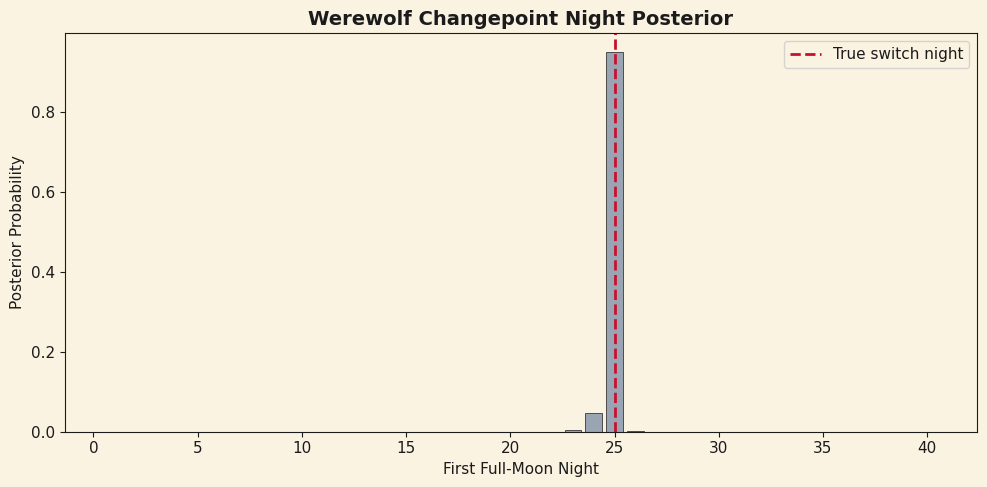

In [5]:
switch_counts = np.bincount(wolf_switch[BURN_IN:], minlength=N_NIGHTS + 1)[1:]
switch_prob = switch_counts / switch_counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(nights, switch_prob, color=PALETTE["silver"], edgecolor=PALETTE["black"], linewidth=0.5)
ax.axvline(TRUE_SWITCH, color=PALETTE["red"], linestyle="--", linewidth=2, label="True switch night")
ax.set_xlabel("First Full-Moon Night")
ax.set_ylabel("Posterior Probability")
ax.set_title("Werewolf Changepoint Night Posterior")
ax.legend()
plt.tight_layout()
plt.savefig("05_changepoint_posterior.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 6 — How well do the fitted rates match?

Bars are the nightly victim counts. The lines are the posterior median rates before and after the most likely switch night, with 95% bands.

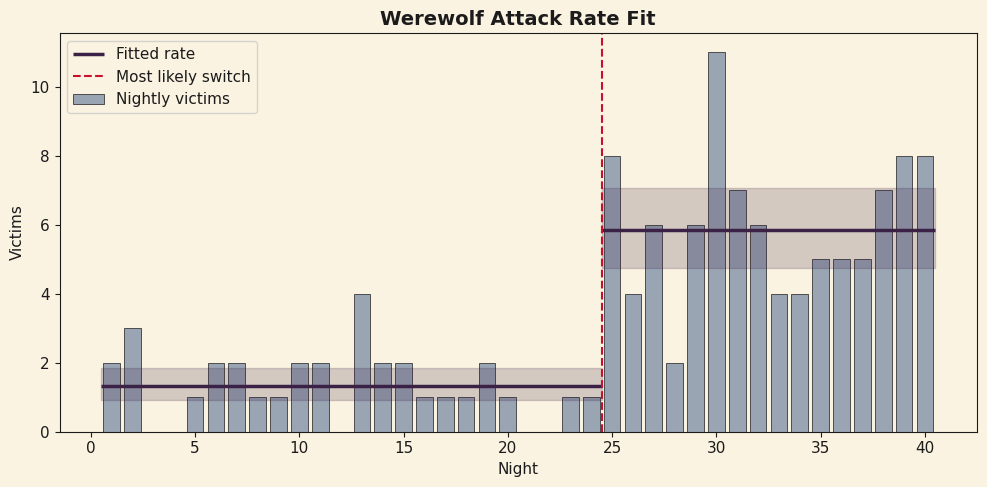

In [6]:
mode_switch = np.argmax(switch_counts) + 1
l1_lo, l1_med, l1_hi = np.percentile(wolf_l1[BURN_IN:], [2.5, 50, 97.5])
l2_lo, l2_med, l2_hi = np.percentile(wolf_l2[BURN_IN:], [2.5, 50, 97.5])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(nights, wolf_y, color=PALETTE["silver"], edgecolor=PALETTE["black"], linewidth=0.5,
       label="Nightly victims")
before, after = nights < mode_switch, nights >= mode_switch
ax.hlines(l1_med, nights[before].min() - 0.5, nights[before].max() + 0.5,
          color=PALETTE["purple"], linewidth=2.5, label="Fitted rate")
ax.hlines(l2_med, nights[after].min() - 0.5, nights[after].max() + 0.5,
          color=PALETTE["purple"], linewidth=2.5)
ax.fill_between([nights[before].min() - 0.5, nights[before].max() + 0.5], l1_lo, l1_hi,
                color=PALETTE["purple"], alpha=0.2)
ax.fill_between([nights[after].min() - 0.5, nights[after].max() + 0.5], l2_lo, l2_hi,
                color=PALETTE["purple"], alpha=0.2)
ax.axvline(mode_switch - 0.5, color=PALETTE["red"], linestyle="--", linewidth=1.5,
           label="Most likely switch")
ax.set_xlabel("Night")
ax.set_ylabel("Victims")
ax.set_title("Werewolf Attack Rate Fit")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("06_werewolf_rate_fit.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 7 — All three monsters, side by side

Same story three times: each panel shows the data against what the sampler learned. Different monsters needed different models — a Normal, a Gamma, and a two-rate changepoint — but the same Gibbs recipe underneath.

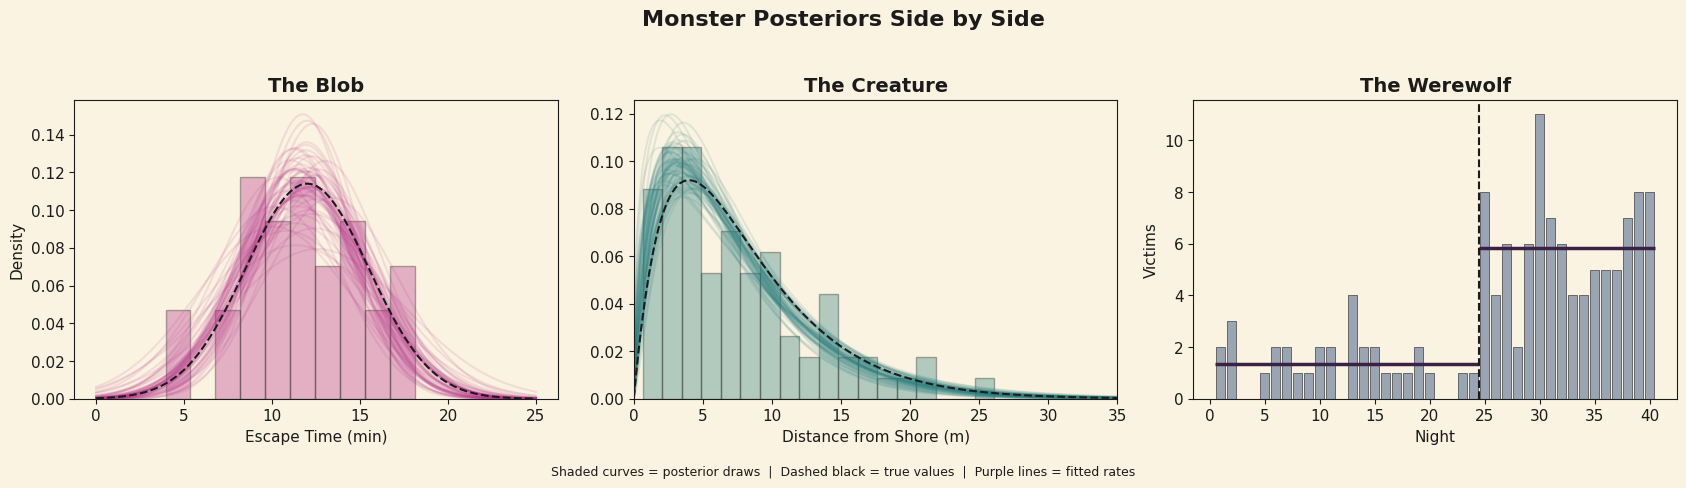

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
idx = np.random.choice(np.arange(BURN_IN, N_ITER), size=60, replace=False)

# Blob
ax = axes[0]
xg = np.linspace(0, 25, 300)
ax.hist(blob_x, bins=10, density=True, color=PALETTE["magenta"], alpha=0.35, edgecolor=PALETTE["black"])
for i in idx:
    ax.plot(xg, stats.norm.pdf(xg, blob_mu[i], blob_sigma[i]), color=PALETTE["magenta"], alpha=0.12)
ax.plot(xg, stats.norm.pdf(xg, TRUE_MU, TRUE_SIGMA), color=PALETTE["black"], linestyle="--", linewidth=1.5)
ax.set_title("The Blob")
ax.set_xlabel("Escape Time (min)")
ax.set_ylabel("Density")

# Creature
ax = axes[1]
xg = np.linspace(0.01, 35, 400)
ax.hist(creature_x, bins=18, density=True, color=PALETTE["teal"], alpha=0.35, edgecolor=PALETTE["black"])
for i in idx:
    ax.plot(xg, stats.gamma.pdf(xg, creature_shape[i], scale=1 / creature_rate[i]),
            color=PALETTE["teal"], alpha=0.12)
ax.plot(xg, stats.gamma.pdf(xg, TRUE_SHAPE, scale=1 / TRUE_RATE), color=PALETTE["black"],
        linestyle="--", linewidth=1.5)
ax.set_xlim(0, 35)
ax.set_title("The Creature")
ax.set_xlabel("Distance from Shore (m)")

# Werewolf
ax = axes[2]
ax.bar(nights, wolf_y, color=PALETTE["silver"], edgecolor=PALETTE["black"], linewidth=0.4)
ax.hlines(l1_med, 0.5, mode_switch - 0.5, color=PALETTE["purple"], linewidth=2.5)
ax.hlines(l2_med, mode_switch - 0.5, N_NIGHTS + 0.5, color=PALETTE["purple"], linewidth=2.5)
ax.axvline(TRUE_SWITCH - 0.5, color=PALETTE["black"], linestyle="--", linewidth=1.5)
ax.set_title("The Werewolf")
ax.set_xlabel("Night")
ax.set_ylabel("Victims")

fig.suptitle("Monster Posteriors Side by Side", fontsize=16, fontweight="bold")
fig.text(0.5, 0.01, "Shaded curves = posterior draws  |  Dashed black = true values  |  Purple lines = fitted rates",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.savefig("07_monsters_combined.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Up next

Week 5 closes the series with Thompson Sampling.